# 08 - Evaluation and analysis

**Goal:** compare all the models and explain the results. **No training here**: everything is loaded from
`results/` and `models/` (notebooks 06 and 07).

| Section | For the report |
|---|---|
| 1. Comparison table | Main results |
| 2. Metric and time charts | Performance vs cost |
| 3. F1 per class | Which attacks each model handles |
| 4. Best model in detail | Classification report, confusion matrix |
| 5. Error analysis | Confusions, missed attacks, false alarms |
| 6. Explainability | Feature importance, SHAP |
| 7. Conclusions | Critical analysis |

**Main metric: macro-F1.** With imbalanced classes, accuracy is misleading. We also use a security view:
the **detection rate** (attacks caught) and the **false alarm rate** (Benign flows flagged).

In [1]:
# Imports
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
from IPython.display import display
from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Paths
BASE = Path("/content/drive/MyDrive/Projects/CSE-CIC-IDS2018")
DATA_DIR = BASE / "data" / "processed"
READY_DIR = BASE / "data" / "model_ready"
MODELS_DIR = BASE / "models"
RESULTS_DIR = BASE / "results"
FIG_DIR = BASE / "figures"
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.max_columns", 100)

Mounted at /content/drive


## 0. Load the test data and the results

In [2]:
X_test = pd.read_parquet(READY_DIR / "X_test.parquet")
y_test = np.load(READY_DIR / "y_test.npy")
encoder = joblib.load(READY_DIR / "label_encoder.joblib")
class_names = list(encoder.classes_)
BENIGN = class_names.index("Benign")

results = pd.DataFrame([json.load(open(f)) for f in RESULTS_DIR.glob("*_metrics.json")])
results = results.set_index("model").sort_values("macro_f1", ascending=False)

preds = {m: np.load(RESULTS_DIR / f"{m}_y_pred.npy") for m in results.index}
print("Models found:", list(results.index))

Models found: ['SoftVoting', 'RandomForest', 'DecisionTree', 'XGBoost', 'LightGBM', 'LightGBM_tuned', 'MLP', 'CNN1D', 'LogisticRegression']


## 1. Comparison table

In [3]:
results.to_csv(RESULTS_DIR / "final_comparison.csv")

results.round(4).style.background_gradient(cmap="Greens", subset=["macro_f1", "balanced_accuracy"]) \
                      .background_gradient(cmap="Reds", subset=["false_alarm_rate"])

,macro_f1,accuracy,balanced_accuracy,weighted_f1,detection_rate,false_alarm_rate,train_time_s
model,,,,,,,
SoftVoting,0.891500,0.885300,0.960700,0.912200,0.983400,0.193500,nan
RandomForest,0.891000,0.896600,0.954600,0.919500,0.979800,0.170100,243.693900
DecisionTree,0.888800,0.875600,0.943800,0.905200,0.978100,0.206600,35.839300
XGBoost,0.882200,0.868200,0.955100,0.900400,0.983000,0.224000,539.458900
LightGBM,0.857400,0.875200,0.959700,0.905300,0.984500,0.212600,454.118800
LightGBM_tuned,0.856600,0.873000,0.958400,0.903700,0.983700,0.215800,1365.133300
MLP,0.810800,0.806700,0.944500,0.856000,0.978700,0.330500,177.101200
CNN1D,0.797300,0.810200,0.934000,0.858000,0.971600,0.316900,82.420100
LogisticRegression,0.794600,0.771700,0.930500,0.828600,0.971700,0.386300,294.382300


## 2. Main metrics and training time

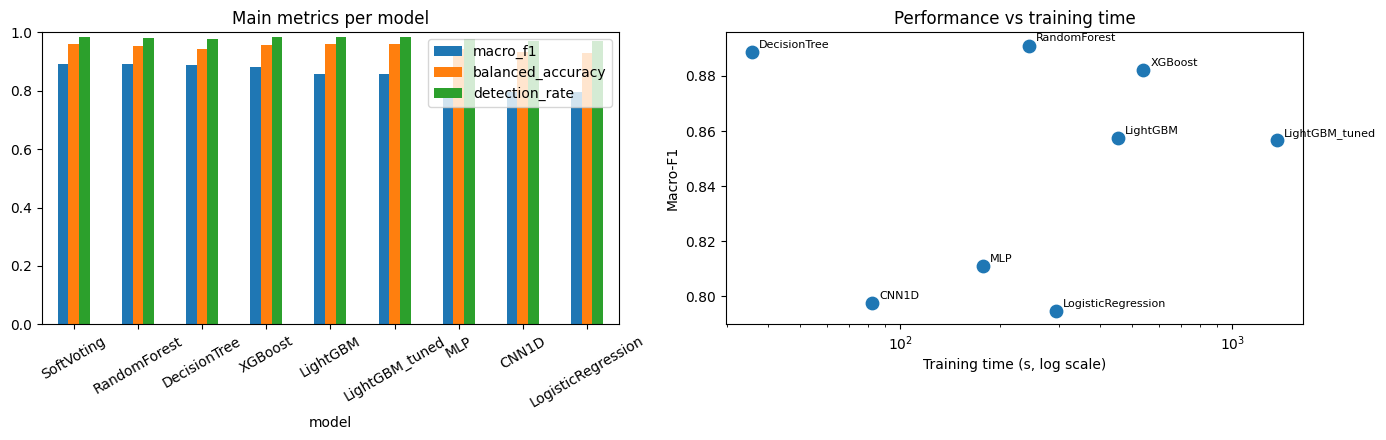

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

results[["macro_f1", "balanced_accuracy", "detection_rate"]].plot(kind="bar", ax=axes[0])
axes[0].set_ylim(0, 1)
axes[0].set_title("Main metrics per model")
axes[0].tick_params(axis="x", rotation=30)

timed = results.dropna(subset=["train_time_s"])
axes[1].scatter(timed["train_time_s"], timed["macro_f1"], s=80)
for name, row in timed.iterrows():
    axes[1].annotate(name, (row["train_time_s"], row["macro_f1"]), fontsize=8,
                     xytext=(5, 3), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Training time (s, log scale)")
axes[1].set_ylabel("Macro-F1")
axes[1].set_title("Performance vs training time")

plt.tight_layout()
plt.savefig(FIG_DIR / "08_model_comparison.png", dpi=150)
plt.show()

## 3. F1-score per class and per model
The most useful view: a good average can hide attacks that are badly detected.

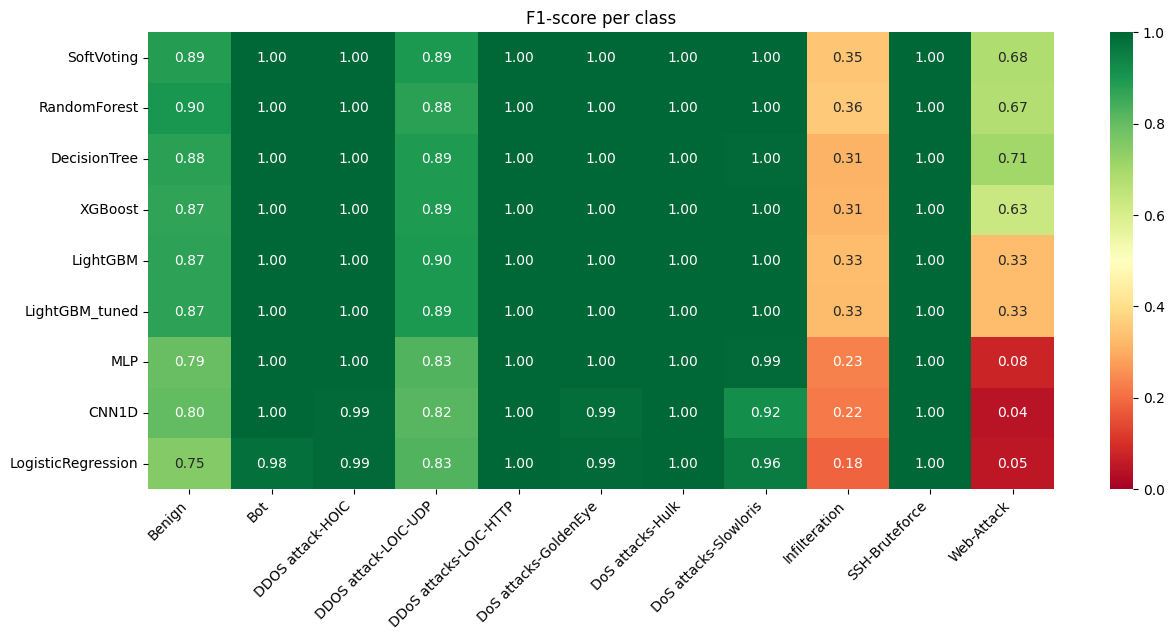

In [5]:
from sklearn.metrics import f1_score

per_class = pd.DataFrame(
    {m: f1_score(y_test, p, average=None, labels=range(len(class_names)), zero_division=0)
     for m, p in preds.items()},
    index=class_names).T

plt.figure(figsize=(len(class_names) + 2, 0.5 * len(preds) + 2))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("F1-score per class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_f1_per_class.png", dpi=150)
plt.show()

## 4. Best model in detail

In [6]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = results["macro_f1"].idxmax()
y_best = preds[best]

print("Best model (macro-F1):", best)
print(classification_report(y_test, y_best, target_names=class_names, digits=4, zero_division=0))

Best model (macro-F1): SoftVoting
                        precision    recall  f1-score   support

                Benign     0.9837    0.8065    0.8863    328660
                   Bot     0.9999    1.0000    0.9999     28907
      DDOS attack-HOIC     1.0000    1.0000    1.0000     39772
  DDOS attack-LOIC-UDP     0.8132    0.9942    0.8947       346
DDoS attacks-LOIC-HTTP     0.9999    0.9993    0.9996    115003
 DoS attacks-GoldenEye     0.9996    0.9996    0.9996      8278
      DoS attacks-Hulk     0.9999    1.0000    0.9999     29040
 DoS attacks-Slowloris     0.9985    1.0000    0.9992      1942
         Infilteration     0.2202    0.8034    0.3457     22295
        SSH-Bruteforce     0.9998    1.0000    0.9999     18808
            Web-Attack     0.5273    0.9647    0.6819       170

              accuracy                         0.8853    593221
             macro avg     0.8675    0.9607    0.8915    593221
          weighted avg     0.9614    0.8853    0.9122    593221



### Confusion matrix
Normalized by row: each row shows how the flows of one **true** class were predicted. The diagonal is the recall.

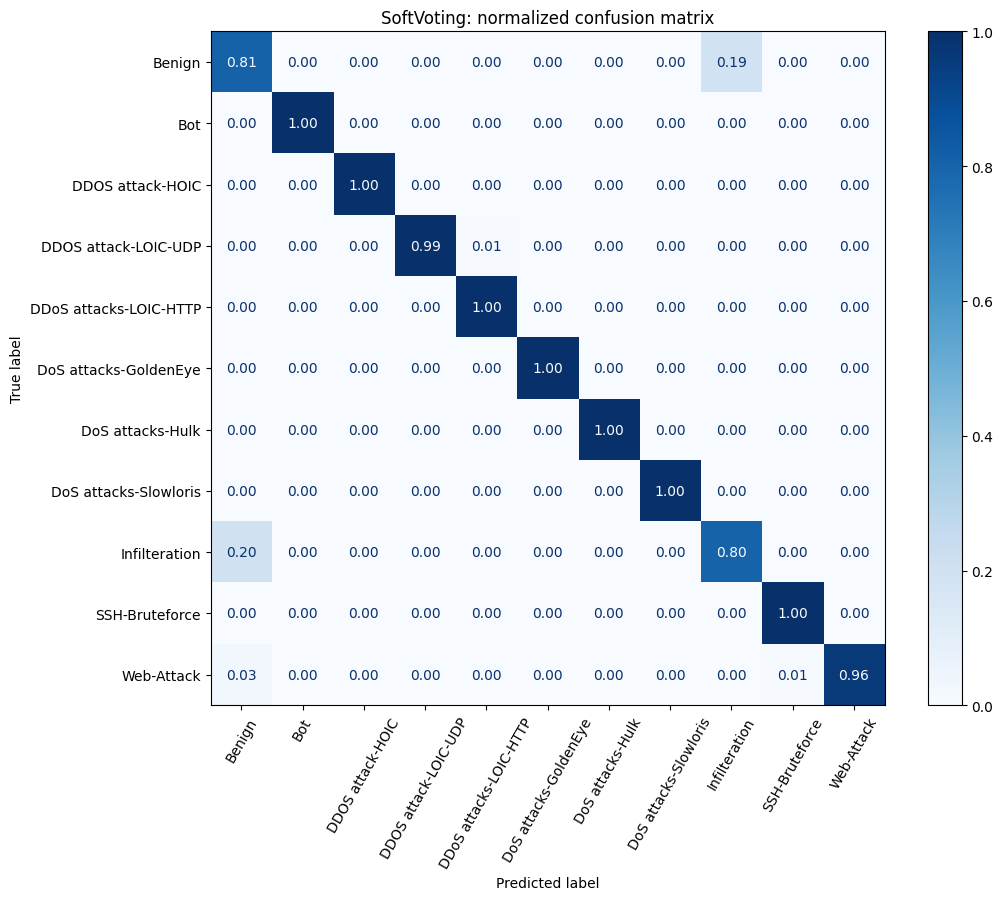

In [7]:
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_best, display_labels=class_names, normalize="true",
    values_format=".2f", cmap="Blues", xticks_rotation=60, ax=ax)
ax.set_title(f"{best}: normalized confusion matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_confusion_matrix.png", dpi=150)
plt.show()

## 5. Error analysis
### 5.1 Most frequent confusions (best model)

In [8]:
errors = pd.DataFrame({"true": np.array(class_names)[y_test],
                       "predicted": np.array(class_names)[y_best]})
errors = errors[errors["true"] != errors["predicted"]]

confusions = errors.value_counts().rename("count").reset_index()
confusions["share_of_true_class"] = (
    confusions["count"] / confusions["true"].map(pd.Series(np.array(class_names)[y_test]).value_counts())
).round(4)
confusions.head(15)

,true,predicted,count,share_of_true_class
0,Benign,Infilteration,63429,0.1930
1,Infilteration,Benign,4382,0.1965
2,Benign,Web-Attack,146,0.0004
3,DDoS attacks-LOIC-HTTP,DDOS attack-LOIC-UDP,79,0.0007
4,Benign,DDoS attacks-LOIC-HTTP,10,0.0000
5,Web-Attack,Benign,5,0.0294
6,Benign,DoS attacks-Slowloris,3,0.0000
7,Benign,DoS attacks-GoldenEye,3,0.0000
8,Benign,SSH-Bruteforce,3,0.0000
9,DoS attacks-GoldenEye,DoS attacks-Hulk,3,0.0004


### 5.2 Security view: attack vs benign
For a bank, the two costly errors are different:
- **Missed attack** (attack predicted as Benign): an intrusion goes unnoticed
- **False alarm** (Benign predicted as an attack): wasted analyst time

Confusing two attack types (e.g. DoS Hulk vs GoldenEye) is less serious: the flow is still flagged.

In [9]:
rows = []
for m, p in preds.items():
    is_attack, pred_attack = y_test != BENIGN, p != BENIGN
    rows.append({
        "model": m,
        "attacks_caught": (is_attack & pred_attack).sum(),
        "attacks_missed": (is_attack & ~pred_attack).sum(),
        "false_alarms": (~is_attack & pred_attack).sum(),
    })
pd.DataFrame(rows).set_index("model").sort_values("attacks_missed")

,attacks_caught,attacks_missed,false_alarms
model,,,
LightGBM,260466,4095,69865
LightGBM_tuned,260238,4323,70920
SoftVoting,260174,4387,63596
XGBoost,260061,4500,73615
RandomForest,259220,5341,55895
MLP,258915,5646,108610
DecisionTree,258771,5790,67888
LogisticRegression,257084,7477,126962
CNN1D,257060,7501,104141


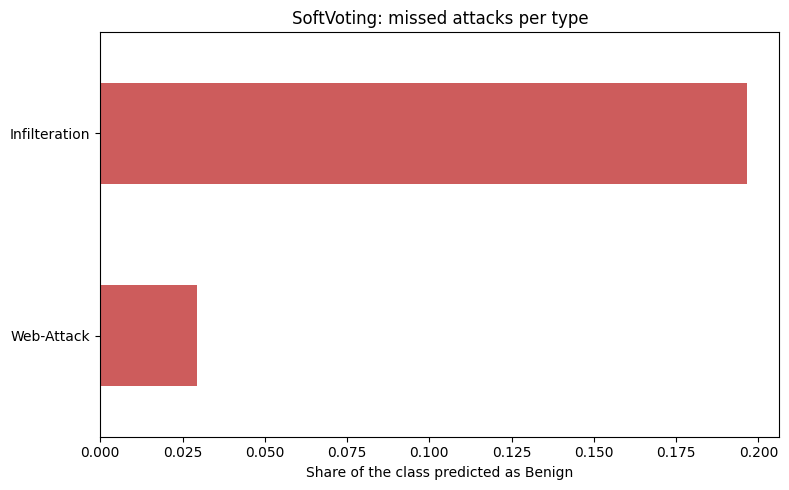

In [10]:
# Which attacks are missed (predicted as Benign) by the best model?
true_names = pd.Series(np.array(class_names)[y_test])
missed = true_names[(y_best == BENIGN) & (y_test != BENIGN)].value_counts()
missed_share = (missed / true_names.value_counts()).dropna().sort_values()

ax = missed_share.plot(kind="barh", figsize=(8, 5), color="indianred")
ax.set_xlabel("Share of the class predicted as Benign")
ax.set_title(f"{best}: missed attacks per type")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_missed_attacks.png", dpi=150)
plt.show()

**To discuss in the report** (check against your results):
- **Infilteration** is often the hardest class: the attacker is already inside the network and the flows look normal.
- **DoS variants** can be confused with each other: they all flood a web server.
- Small classes (Web-Attack, LOIC-UDP) have few test rows, so their scores are less reliable.

## 6. Explainability
### 6.1 Feature importance (best tree model)
How much each feature is used by the model to split the data.

Explaining: RandomForest


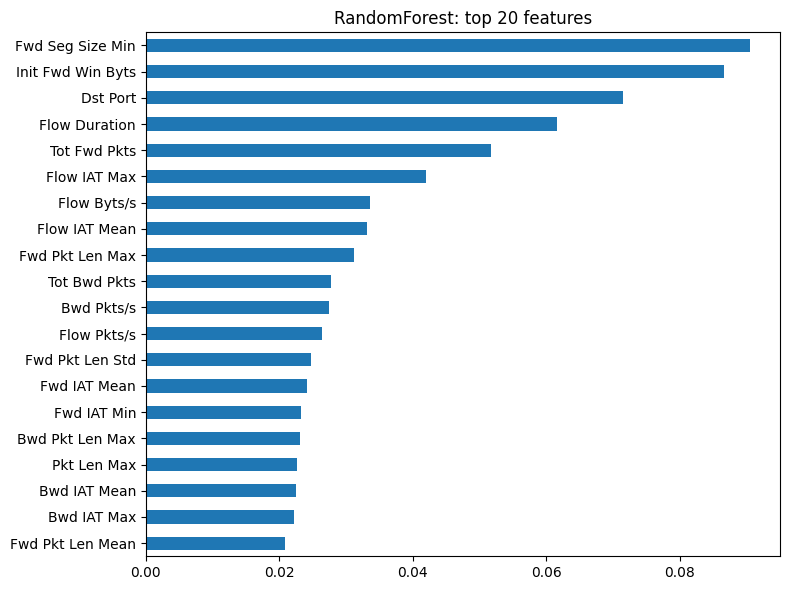

In [11]:
TREE_MODELS = ["LightGBM_tuned", "LightGBM", "XGBoost", "RandomForest", "DecisionTree"]
available = [m for m in TREE_MODELS if m in results.index and (MODELS_DIR / f"{m}.joblib").exists()]
best_tree = max(available, key=lambda m: results.loc[m, "macro_f1"])
tree_model = joblib.load(MODELS_DIR / f"{best_tree}.joblib")
print("Explaining:", best_tree)

importance = pd.Series(tree_model.feature_importances_, index=X_test.columns).sort_values()
ax = importance.tail(20).plot(kind="barh", figsize=(8, 6))
ax.set_title(f"{best_tree}: top 20 features")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_feature_importance.png", dpi=150)
plt.show()

### 6.2 SHAP
Feature importance only says *how much* a feature is used. **SHAP** also shows *in which direction* it pushes
the prediction, for each class. It is slow, so it runs on a small sample (about 100 rows per class).

In [12]:
!pip install -q shap

In [13]:
import shap

s = pd.Series(y_test).sample(frac=1, random_state=SEED)
idx = s.groupby(s).head(100).index
X_shap = X_test.iloc[idx]

explainer = shap.TreeExplainer(tree_model)
shap_values = explainer.shap_values(X_shap)
if isinstance(shap_values, list):                     # older SHAP versions: one array per class
    shap_values = np.stack(shap_values, axis=-1)
print("SHAP values shape (rows, features, classes):", shap_values.shape)

SHAP values shape (rows, features, classes): (1100, 49, 11)


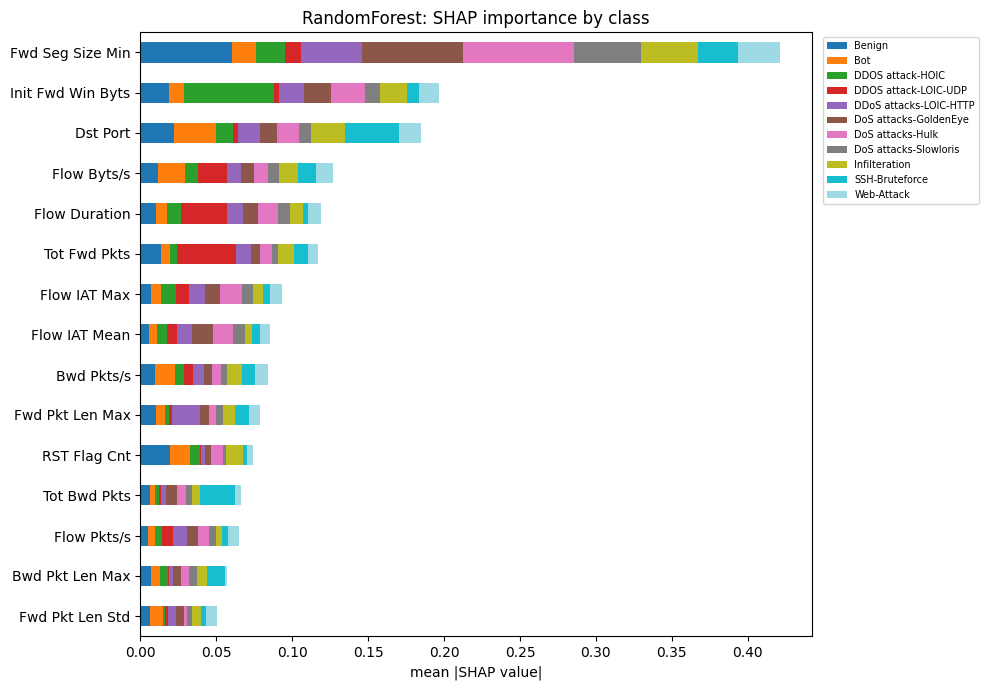

In [14]:
# Global importance: mean |SHAP| per feature, split by class
mean_abs = pd.DataFrame(np.abs(shap_values).mean(axis=0), index=X_test.columns, columns=class_names)
top = mean_abs.sum(axis=1).sort_values().tail(15).index

ax = mean_abs.loc[top].plot(kind="barh", stacked=True, figsize=(10, 7), colormap="tab20")
ax.set_xlabel("mean |SHAP value|")
ax.set_title(f"{best_tree}: SHAP importance by class")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_shap_global.png", dpi=150)
plt.show()

### 6.3 SHAP for one class
Each dot is a flow. Red = high feature value, blue = low. Right = pushes toward this class.
By default we explain the attack class with the **lowest recall**.

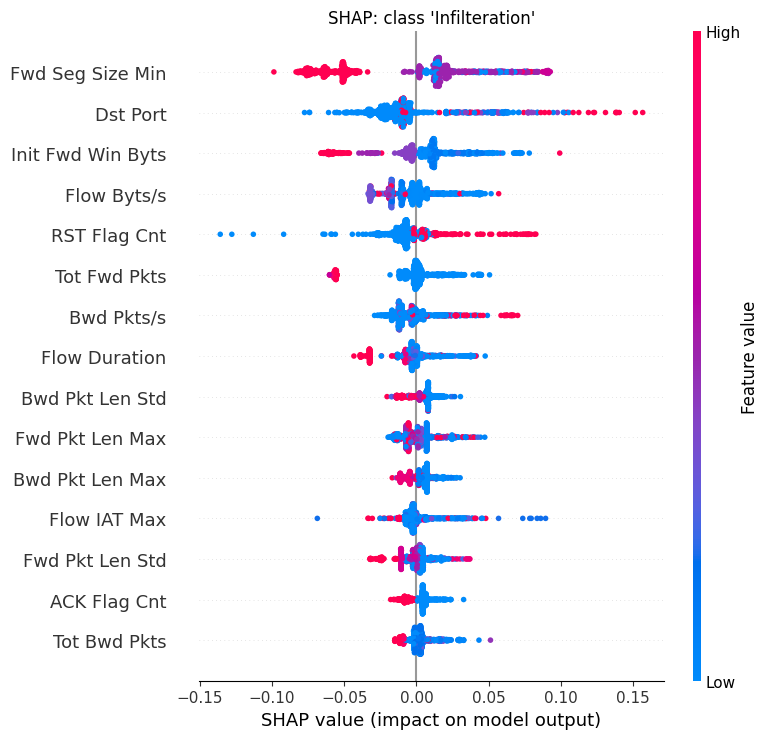

In [15]:
from sklearn.metrics import recall_score

recalls = pd.Series(recall_score(y_test, y_best, average=None, labels=range(len(class_names)),
                                 zero_division=0), index=class_names).drop("Benign")
CLASS_TO_EXPLAIN = recalls.idxmin()            # or e.g. "DoS attacks-Hulk"
k = class_names.index(CLASS_TO_EXPLAIN)

shap.summary_plot(shap_values[:, :, k], X_shap, max_display=15, show=False)
plt.title(f"SHAP: class '{CLASS_TO_EXPLAIN}'")
plt.tight_layout()
plt.show()

## 7. Conclusions

**Results**
- Best model: **SoftVoting** (macro-F1 **0.8915**, detection rate **0.9834** for attacks, false alarm rate **0.1930** for benign flows)
- Tree models vs neural networks: Tree-based ensembles (**RandomForest**, **DecisionTree**, **XGBoost**, and **LightGBM**) significantly outperformed the deep learning models (**MLP**, **CNN1D**) and traditional models (**LogisticRegression**) in both macro-F1 and training time.
- Soft voting and Optuna: Combining individual tree and neural network predictions via a **SoftVoting** meta-classifier succeeded in boosting the final macro-F1 slightly higher than any single standalone model.

**Error analysis**
- Hardest classes and why: **Infiltration** is the hardest class by far (recall ~80.34%, F1-score ~0.35). This is because the attacker operates with credentials or inside-network access, generating traffic patterns that closely mimic normal (**Benign**) flows.
- Main confusions: The most frequent misclassifications occur between **Benign** and **Infiltration** (accounting for 19.3% of benign flows being flagged as infiltration and 19.65% of actual infiltration flows being missed as benign).

**Explainability**
- Most important features and what they mean:
  - **Fwd Seg Size Min**: Reflects the minimum segment size observed in the forward direction (highly indicative of the TCP configuration differences between operating systems or automated attack scripts and user devices).
  - **Init Fwd Win Byts**: The number of bytes sent in the initial window in the forward direction (often hardcoded or distinct in malicious payloads/connection setups).
  - **Dst Port**: The destination port of the traffic (e.g., targeting specific ports like 80 for Web-Attacks and DoS, or higher random ports for background infiltration).

**Limitations**
- Synthetic traffic generated in a lab (AWS), not a real bank network
- Known quality issues in CSE-CIC-IDS2018: 26% duplicates, labeling problems, some classes almost empty after cleaning
- Benign was subsampled to 15%; real traffic would be even more imbalanced
- Random train/test split from the same days: optimistic compared to detecting **new** attacks

**Possible improvements**
- Test on another dataset (e.g. CIC-IDS2017) to check generalization
- Split by day instead of randomly (harder, more realistic)
- Two stages: a binary detector (attack / benign), then a classifier for the attack type